# Experiment 4: Karman Vortex Street over a Cylinder

**Aim:** Resolve alternating vortex shedding behind a circular cylinder and estimate the Strouhal number.

**Numerical method:** D2Q9 BGK lattice Boltzmann method with bounce-back cylinder treatment and momentum-exchange forces.

> **Scope:** The laboratory case is weakly compressible in lattice units. The lab preset is validated for periodic shedding near $St=0.167$ at $Re=100$.

This Google Colab notebook is self-contained. It reconstructs the tested solver inside the temporary Colab runtime, runs it, displays quantitative plots and an inline field contour, and packages every output file for download.

> **Colab workflow:** Choose a run mode, use **Runtime > Run all**, then download the results ZIP from the final cell. `quick` is only a workflow check; use `lab` or an approved `custom` case for submission.

In [1]:
#@title 1. Prepare the self-contained Colab runtime

from pathlib import Path
import shutil
import subprocess
import sys
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

IN_COLAB = False
try:
    from google.colab import files as colab_files
    IN_COLAB = True
except ImportError:
    colab_files = None


def run_solver(script_path, arguments, output_dir, timeout=1800):
    output_dir = Path(output_dir)
    if output_dir.exists():
        shutil.rmtree(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    command = [sys.executable, str(script_path), *[str(value) for value in arguments]]
    print("Running:", " ".join(command))
    completed = subprocess.run(command, cwd=output_dir, capture_output=True, text=True, timeout=timeout)
    (output_dir / "solver_stdout.log").write_text(completed.stdout, encoding="utf-8")
    (output_dir / "solver_stderr.log").write_text(completed.stderr, encoding="utf-8")
    if completed.stdout.strip():
        print(completed.stdout.strip())
    if completed.returncode != 0:
        raise RuntimeError(completed.stderr.strip() or f"Solver exited with code {completed.returncode}")
    if completed.stderr.strip():
        print(completed.stderr.strip())
    return output_dir


def read_csv(path):
    data = np.genfromtxt(path, delimiter=",", names=True, dtype=None, encoding="utf-8")
    return np.atleast_1d(data)


def show_summary(path):
    text = Path(path).read_text(encoding="utf-8").strip()
    display(Markdown(f"### Solver summary\n```text\n{text}\n```"))
    return text


def list_outputs(output_dir):
    rows = []
    for path in sorted(Path(output_dir).iterdir()):
        if path.is_file():
            size = path.stat().st_size
            if size < 1024:
                size_text = f"{size} B"
            elif size < 1024**2:
                size_text = f"{size / 1024:.1f} KB"
            else:
                size_text = f"{size / 1024**2:.1f} MB"
            rows.append((path.name, size_text))
    table = "\n".join(f"| `{name}` | {size} |" for name, size in rows)
    display(Markdown(f"### Generated files\n| File | Size |\n|---|---:|\n{table}"))
    return rows


def read_structured_vtk(path):
    lines = Path(path).read_text(encoding="utf-8").splitlines()
    dims_index = next(i for i, line in enumerate(lines) if line.startswith("DIMENSIONS "))
    _, nx, ny, nz = lines[dims_index].split()
    nx, ny, nz = int(nx), int(ny), int(nz)
    if nz != 1:
        raise ValueError("Only 2D structured VTK files are supported by this notebook preview")
    points_index = next(i for i, line in enumerate(lines) if line.startswith("POINTS "))
    npoints = int(lines[points_index].split()[1])
    points = np.array([[float(v) for v in lines[points_index + 1 + k].split()[:3]] for k in range(npoints)])
    x = points[:, 0].reshape(ny, nx)
    y = points[:, 1].reshape(ny, nx)
    data_index = next(i for i, line in enumerate(lines) if line.startswith("POINT_DATA ")) + 1
    scalars = {}
    vectors = {}
    i = data_index
    while i < len(lines):
        if lines[i].startswith("SCALARS "):
            name = lines[i].split()[1]
            i += 2
            values = np.array([float(lines[i + k].split()[0]) for k in range(npoints)])
            scalars[name] = values.reshape(ny, nx)
            i += npoints
        elif lines[i].startswith("VECTORS "):
            name = lines[i].split()[1]
            i += 1
            values = np.array([[float(v) for v in lines[i + k].split()[:3]] for k in range(npoints)])
            vectors[name] = (values[:, 0].reshape(ny, nx), values[:, 1].reshape(ny, nx))
            i += npoints
        else:
            i += 1
    return x, y, scalars, vectors


def plot_vtk_scalar(path, preferred_field=None):
    path = Path(path)
    if not path.is_file():
        print(f"VTK preview skipped: {path.name} was not generated")
        return
    x, y, scalars, _ = read_structured_vtk(path)
    if not scalars:
        print("VTK preview skipped: no scalar field found")
        return
    field = preferred_field if preferred_field in scalars else next(iter(scalars))
    plt.figure(figsize=(8, 4.8))
    image = plt.contourf(x, y, scalars[field], levels=30)
    plt.colorbar(image, label=field.replace("_", " "))
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"{field.replace('_', ' ').title()} - inline field preview")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()


def make_results_zip(output_dir, experiment_number):
    output_dir = Path(output_dir)
    archive = output_dir.parent / f"experiment_{experiment_number:02d}_results.zip"
    if archive.exists():
        archive.unlink()
    with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as handle:
        for path in sorted(output_dir.rglob("*")):
            if path.is_file():
                handle.write(path, path.relative_to(output_dir))
    print(f"Results archive: {archive} ({archive.stat().st_size / 1024:.1f} KB)")
    return archive


EXPERIMENT = 4
ROOT = Path("/content/cfd_lab_exp04") if IN_COLAB else Path.cwd() / "_colab_runtime_exp04"
CODE_DIR = ROOT / "code"
OUTPUT_DIR = ROOT / "outputs"
CODE_DIR.mkdir(parents=True, exist_ok=True)
(CODE_DIR / "common.py").write_text('from __future__ import annotations\n\nimport csv\nimport math\nfrom pathlib import Path\nfrom typing import Iterable, Mapping\n\nimport numpy as np\n\n\ndef trapezoidal_integral(values: np.ndarray, coordinates: np.ndarray) -> float:\n    y = np.asarray(values, dtype=float).ravel()\n    x = np.asarray(coordinates, dtype=float).ravel()\n    if y.size != x.size or y.size < 2:\n        raise ValueError("trapezoidal integration requires equally sized arrays with at least two points")\n    return float(np.sum(0.5 * (y[1:] + y[:-1]) * np.diff(x)))\n\n\ndef write_csv(path: str | Path, header: Iterable[str], rows: Iterable[Iterable[object]]) -> None:\n    with Path(path).open("w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(list(header))\n        writer.writerows(rows)\n\n\ndef mesh_xy(nx: int, ny: int, lx: float = 1.0, ly: float = 1.0, x0: float = 0.0, y0: float = 0.0) -> tuple[np.ndarray, np.ndarray]:\n    x = np.linspace(x0, x0 + lx, nx)\n    y = np.linspace(y0, y0 + ly, ny)\n    return np.meshgrid(x, y)\n\n\ndef write_structured_grid_vtk(\n    path: str | Path,\n    x: np.ndarray,\n    y: np.ndarray,\n    scalars: Mapping[str, np.ndarray] | None = None,\n    vectors: Mapping[str, tuple[np.ndarray, np.ndarray]] | None = None,\n    title: str = "CFD lab output",\n) -> None:\n    x = np.asarray(x, dtype=float)\n    y = np.asarray(y, dtype=float)\n    if x.shape != y.shape or x.ndim != 2:\n        raise ValueError("x and y must be equally shaped 2D arrays")\n    ny, nx = x.shape\n    scalar_map = dict(scalars or {})\n    vector_map = dict(vectors or {})\n    for name, values in scalar_map.items():\n        if np.asarray(values).shape != x.shape:\n            raise ValueError(f"scalar {name} has shape {np.asarray(values).shape}, expected {x.shape}")\n    for name, values in vector_map.items():\n        if len(values) != 2 or np.asarray(values[0]).shape != x.shape or np.asarray(values[1]).shape != x.shape:\n            raise ValueError(f"vector {name} has incompatible shape")\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET STRUCTURED_GRID\\n")\n        handle.write(f"DIMENSIONS {nx} {ny} 1\\n")\n        handle.write(f"POINTS {nx * ny} float\\n")\n        for j in range(ny):\n            for i in range(nx):\n                handle.write(f"{x[j, i]:.12e} {y[j, i]:.12e} 0\\n")\n        handle.write(f"POINT_DATA {nx * ny}\\n")\n        for name, values in scalar_map.items():\n            data = np.asarray(values, dtype=float)\n            handle.write(f"SCALARS {name} float 1\\n")\n            handle.write("LOOKUP_TABLE default\\n")\n            for value in data.ravel(order="C"):\n                handle.write(f"{value:.12e}\\n")\n        for name, values in vector_map.items():\n            vx = np.asarray(values[0], dtype=float)\n            vy = np.asarray(values[1], dtype=float)\n            handle.write(f"VECTORS {name} float\\n")\n            for ax, ay in zip(vx.ravel(order="C"), vy.ravel(order="C")):\n                handle.write(f"{ax:.12e} {ay:.12e} 0\\n")\n\n\ndef write_polyline_vtk(path: str | Path, x: np.ndarray, y: np.ndarray, title: str = "polyline", close: bool = False) -> None:\n    x = np.asarray(x, dtype=float).ravel()\n    y = np.asarray(y, dtype=float).ravel()\n    if x.size != y.size or x.size < 2:\n        raise ValueError("polyline requires equally sized x and y arrays")\n    ids = list(range(x.size))\n    if close:\n        ids.append(0)\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {x.size} float\\n")\n        for xi, yi in zip(x, y):\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"LINES 1 {len(ids) + 1}\\n")\n        handle.write(f"{len(ids)} {\' \'.join(str(i) for i in ids)}\\n")\n\n\ndef write_multiline_vtk(path: str | Path, lines: list[tuple[np.ndarray, np.ndarray]], title: str = "lines") -> None:\n    points: list[tuple[float, float]] = []\n    connectivity: list[list[int]] = []\n    for x, y in lines:\n        xa = np.asarray(x, dtype=float).ravel()\n        ya = np.asarray(y, dtype=float).ravel()\n        if xa.size != ya.size or xa.size < 2:\n            raise ValueError("each line needs equally sized x and y arrays")\n        ids = list(range(len(points), len(points) + xa.size))\n        points.extend(zip(xa.tolist(), ya.tolist()))\n        connectivity.append(ids)\n    size = sum(len(ids) + 1 for ids in connectivity)\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {len(points)} float\\n")\n        for xi, yi in points:\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"LINES {len(connectivity)} {size}\\n")\n        for ids in connectivity:\n            handle.write(f"{len(ids)} {\' \'.join(str(i) for i in ids)}\\n")\n\n\ndef write_points_vtk(path: str | Path, x: np.ndarray, y: np.ndarray, scalars: Mapping[str, np.ndarray] | None = None, title: str = "points") -> None:\n    xa = np.asarray(x, dtype=float).ravel()\n    ya = np.asarray(y, dtype=float).ravel()\n    if xa.size != ya.size:\n        raise ValueError("point arrays must have equal size")\n    scalar_map = dict(scalars or {})\n    with Path(path).open("w", encoding="utf-8") as handle:\n        handle.write("# vtk DataFile Version 3.0\\n")\n        handle.write(f"{title}\\n")\n        handle.write("ASCII\\n")\n        handle.write("DATASET POLYDATA\\n")\n        handle.write(f"POINTS {xa.size} float\\n")\n        for xi, yi in zip(xa, ya):\n            handle.write(f"{xi:.12e} {yi:.12e} 0\\n")\n        handle.write(f"VERTICES {xa.size} {2 * xa.size}\\n")\n        for i in range(xa.size):\n            handle.write(f"1 {i}\\n")\n        if scalar_map:\n            handle.write(f"POINT_DATA {xa.size}\\n")\n            for name, values in scalar_map.items():\n                data = np.asarray(values, dtype=float).ravel()\n                if data.size != xa.size:\n                    raise ValueError(f"scalar {name} has wrong size")\n                handle.write(f"SCALARS {name} float 1\\n")\n                handle.write("LOOKUP_TABLE default\\n")\n                for value in data:\n                    handle.write(f"{value:.12e}\\n")\n\n\ndef gradient(field: np.ndarray, dx: float, dy: float) -> tuple[np.ndarray, np.ndarray]:\n    gy, gx = np.gradient(field, dy, dx, edge_order=2)\n    return gx, gy\n\n\ndef laplacian(field: np.ndarray, dx: float, dy: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    out[1:-1, 1:-1] = (\n        (field[1:-1, 2:] - 2.0 * field[1:-1, 1:-1] + field[1:-1, :-2]) / (dx * dx)\n        + (field[2:, 1:-1] - 2.0 * field[1:-1, 1:-1] + field[:-2, 1:-1]) / (dy * dy)\n    )\n    return out\n\n\ndef upwind_derivative_x(field: np.ndarray, velocity: np.ndarray, dx: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    backward = (field[1:-1, 1:-1] - field[1:-1, :-2]) / dx\n    forward = (field[1:-1, 2:] - field[1:-1, 1:-1]) / dx\n    out[1:-1, 1:-1] = np.where(velocity[1:-1, 1:-1] >= 0.0, backward, forward)\n    return out\n\n\ndef upwind_derivative_y(field: np.ndarray, velocity: np.ndarray, dy: float) -> np.ndarray:\n    out = np.zeros_like(field)\n    backward = (field[1:-1, 1:-1] - field[:-2, 1:-1]) / dy\n    forward = (field[2:, 1:-1] - field[1:-1, 1:-1]) / dy\n    out[1:-1, 1:-1] = np.where(velocity[1:-1, 1:-1] >= 0.0, backward, forward)\n    return out\n\n\ndef poisson_jacobi(phi: np.ndarray, rhs: np.ndarray, dx: float, dy: float, iterations: int, boundary: str = "neumann", mask: np.ndarray | None = None) -> np.ndarray:\n    dx2 = dx * dx\n    dy2 = dy * dy\n    denom = 2.0 * (dx2 + dy2)\n    for _ in range(iterations):\n        old = phi.copy()\n        phi[1:-1, 1:-1] = (\n            (old[1:-1, 2:] + old[1:-1, :-2]) * dy2\n            + (old[2:, 1:-1] + old[:-2, 1:-1]) * dx2\n            - rhs[1:-1, 1:-1] * dx2 * dy2\n        ) / denom\n        if mask is not None:\n            phi[mask > 0.5] = 0.0\n        if boundary == "neumann":\n            phi[:, 0] = phi[:, 1]\n            phi[:, -1] = 0.0\n            phi[0, :] = phi[1, :]\n            phi[-1, :] = phi[-2, :]\n        elif boundary == "closed":\n            phi[:, 0] = phi[:, 1]\n            phi[:, -1] = phi[:, -2]\n            phi[0, :] = phi[1, :]\n            phi[-1, :] = phi[-2, :]\n            phi -= np.mean(phi)\n        else:\n            raise ValueError("unsupported pressure boundary")\n    return phi\n\n\ndef tdma(a: np.ndarray, b: np.ndarray, c: np.ndarray, d: np.ndarray) -> np.ndarray:\n    a = np.asarray(a, dtype=float).copy()\n    b = np.asarray(b, dtype=float).copy()\n    c = np.asarray(c, dtype=float).copy()\n    d = np.asarray(d, dtype=float).copy()\n    n = d.size\n    if n == 0 or a.size != n or b.size != n or c.size != n:\n        raise ValueError("TDMA arrays must have equal nonzero size")\n    for i in range(1, n):\n        if abs(b[i - 1]) < 1e-30:\n            raise FloatingPointError("zero TDMA pivot")\n        factor = a[i] / b[i - 1]\n        b[i] -= factor * c[i - 1]\n        d[i] -= factor * d[i - 1]\n    x = np.empty(n, dtype=float)\n    if abs(b[-1]) < 1e-30:\n        raise FloatingPointError("zero TDMA pivot")\n    x[-1] = d[-1] / b[-1]\n    for i in range(n - 2, -1, -1):\n        if abs(b[i]) < 1e-30:\n            raise FloatingPointError("zero TDMA pivot")\n        x[i] = (d[i] - c[i] * x[i + 1]) / b[i]\n    return x\n\n\ndef relative_l2(numerical: np.ndarray, reference: np.ndarray) -> float:\n    a = np.asarray(numerical, dtype=float)\n    b = np.asarray(reference, dtype=float)\n    denominator = float(np.linalg.norm(b.ravel()))\n    numerator = float(np.linalg.norm((a - b).ravel()))\n    return numerator / max(denominator, 1e-30)\n\n\ndef require_finite(*arrays: np.ndarray) -> None:\n    for array in arrays:\n        if not np.all(np.isfinite(array)):\n            raise FloatingPointError("non-finite numerical field detected")\n\n\ndef positive_float(value: str, name: str) -> float:\n    result = float(value)\n    if not math.isfinite(result) or result <= 0.0:\n        raise ValueError(f"{name} must be positive and finite")\n    return result\n\n\ndef positive_int(value: str, name: str, minimum: int = 1) -> int:\n    result = int(value)\n    if result < minimum:\n        raise ValueError(f"{name} must be at least {minimum}")\n    return result\n', encoding="utf-8")
(CODE_DIR / 'exp04_cylinder_karman_vortex.py').write_text('from __future__ import annotations\n\nimport csv\nimport math\nimport sys\n\nimport numpy as np\n\nfrom common import require_finite, write_points_vtk, write_polyline_vtk, write_structured_grid_vtk\n\n\ndef equilibrium(rho: np.ndarray, ux: np.ndarray, uy: np.ndarray, velocities: np.ndarray, weights: np.ndarray) -> np.ndarray:\n    result = np.empty((9, *rho.shape), dtype=float)\n    speed_squared = ux * ux + uy * uy\n    for q, (cx, cy) in enumerate(velocities):\n        cu = cx * ux + cy * uy\n        result[q] = weights[q] * rho * (1.0 + 3.0 * cu + 4.5 * cu * cu - 1.5 * speed_squared)\n    return result\n\n\ndef estimate_strouhal(lift: np.ndarray, sample_spacing: float, diameter_lattice: float, inlet_speed_lattice: float) -> float:\n    if lift.size < 64:\n        return 0.0\n    start = lift.size // 2\n    signal = lift[start:] - np.mean(lift[start:])\n    if float(np.std(signal)) < 1e-5:\n        return 0.0\n    spectrum = np.abs(np.fft.rfft(signal * np.hanning(signal.size))) ** 2\n    frequency = np.fft.rfftfreq(signal.size, d=sample_spacing)\n    strouhal = frequency * diameter_lattice / inlet_speed_lattice\n    admissible = (strouhal >= 0.05) & (strouhal <= 0.35)\n    if not np.any(admissible):\n        return 0.0\n    return float(strouhal[admissible][np.argmax(spectrum[admissible])])\n\n\ndef main() -> int:\n    nx = int(sys.argv[1]) if len(sys.argv) > 1 else 181\n    ny = int(sys.argv[2]) if len(sys.argv) > 2 else 81\n    reynolds = float(sys.argv[3]) if len(sys.argv) > 3 else 100.0\n    steps = int(sys.argv[4]) if len(sys.argv) > 4 else 1200\n    legacy_iterations = int(sys.argv[5]) if len(sys.argv) > 5 else 45\n    output_every = int(sys.argv[6]) if len(sys.argv) > 6 else 300\n    if nx < 31 or ny < 17 or reynolds < 20.0 or steps < 1 or legacy_iterations < 1 or output_every < 1:\n        raise ValueError("usage: python exp04_cylinder_karman_vortex.py nx ny Re steps numerical_iterations output_every")\n    substeps = max(1, min(4, int(round(legacy_iterations / 10.0))))\n    inlet_speed = 0.10\n    diameter = max(4, int(round(ny / 8.0)))\n    radius = 0.5 * diameter\n    center_x = int(round(0.25 * nx))\n    center_y = 0.5 * (ny - 1)\n    nu = inlet_speed * diameter / reynolds\n    tau = 0.5 + 3.0 * nu\n    if tau <= 0.505:\n        raise ValueError("LBM relaxation time is too close to 0.5; increase ny or reduce Reynolds number")\n    relaxation = 1.0 / tau\n    velocities = np.array([[0, 0], [1, 0], [0, 1], [-1, 0], [0, -1], [1, 1], [-1, 1], [-1, -1], [1, -1]], dtype=int)\n    weights = np.array([4.0 / 9.0, 1.0 / 9.0, 1.0 / 9.0, 1.0 / 9.0, 1.0 / 9.0, 1.0 / 36.0, 1.0 / 36.0, 1.0 / 36.0, 1.0 / 36.0])\n    opposite = np.array([0, 3, 4, 1, 2, 7, 8, 5, 6], dtype=int)\n    j_grid, i_grid = np.mgrid[0:ny, 0:nx]\n    solid = (i_grid - center_x) ** 2 + (j_grid - center_y) ** 2 <= radius * radius\n    fluid = ~solid\n    rho = np.ones((ny, nx), dtype=float)\n    ux = np.full((ny, nx), inlet_speed, dtype=float)\n    uy = 0.05 * inlet_speed * np.sin(2.0 * math.pi * j_grid / ny) * np.exp(-((i_grid - center_x) / (2.0 * diameter)) ** 2)\n    ux[solid] = 0.0\n    uy[solid] = 0.0\n    populations = equilibrium(rho, ux, uy, velocities, weights)\n    populations[:, solid] = 0.0\n    inlet_rho = np.ones((ny, 1), dtype=float)\n    inlet_ux = np.full((ny, 1), inlet_speed, dtype=float)\n    inlet_uy = np.zeros((ny, 1), dtype=float)\n    inlet_equilibrium = equilibrium(inlet_rho, inlet_ux, inlet_uy, velocities, weights)[:, :, 0]\n    history: list[list[float]] = []\n    lattice_time = 0\n    for outer_step in range(1, steps + 1):\n        force_x_accumulated = 0.0\n        force_y_accumulated = 0.0\n        for _ in range(substeps):\n            rho = np.sum(populations, axis=0)\n            safe_rho = np.where(rho > 1e-30, rho, 1.0)\n            ux = np.tensordot(velocities[:, 0], populations, axes=(0, 0)) / safe_rho\n            uy = np.tensordot(velocities[:, 1], populations, axes=(0, 0)) / safe_rho\n            ux[solid] = 0.0\n            uy[solid] = 0.0\n            local_equilibrium = equilibrium(safe_rho, ux, uy, velocities, weights)\n            post_collision = populations - relaxation * (populations - local_equilibrium)\n            post_collision[:, solid] = 0.0\n            streamed = np.zeros_like(populations)\n            for q, (cx, cy) in enumerate(velocities):\n                destination_is_solid = fluid & np.roll(solid, shift=(-cy, -cx), axis=(0, 1))\n                source = post_collision[q]\n                force_x_accumulated += 2.0 * float(np.sum(source[destination_is_solid])) * cx\n                force_y_accumulated += 2.0 * float(np.sum(source[destination_is_solid])) * cy\n                streamed[q] += np.roll(source * (~destination_is_solid), shift=(cy, cx), axis=(0, 1))\n                streamed[opposite[q]][destination_is_solid] += source[destination_is_solid]\n            populations = streamed\n            populations[:, :, 0] = inlet_equilibrium\n            populations[:, :, -1] = populations[:, :, -2]\n            populations[:, solid] = 0.0\n            lattice_time += 1\n        rho = np.sum(populations, axis=0)\n        safe_rho = np.where(rho > 1e-30, rho, 1.0)\n        ux = np.tensordot(velocities[:, 0], populations, axes=(0, 0)) / safe_rho\n        uy = np.tensordot(velocities[:, 1], populations, axes=(0, 0)) / safe_rho\n        ux[solid] = 0.0\n        uy[solid] = 0.0\n        denominator = 0.5 * inlet_speed * inlet_speed * diameter * substeps\n        drag = force_x_accumulated / denominator\n        lift = force_y_accumulated / denominator\n        fluid_density = rho[fluid]\n        maximum_speed = float(np.max(np.sqrt(ux * ux + uy * uy)))\n        density_deviation = float(np.max(np.abs(fluid_density - 1.0)))\n        history.append([outer_step, lattice_time, lattice_time * inlet_speed / diameter, drag, lift, maximum_speed, float(np.min(fluid_density)), float(np.max(fluid_density)), density_deviation])\n        require_finite(rho[fluid], ux[fluid], uy[fluid])\n        if maximum_speed > 0.45 or density_deviation > 0.25:\n            raise FloatingPointError(f"LBM solution became nonphysical at outer step {outer_step}")\n        if outer_step % output_every == 0 or outer_step == steps:\n            physical_x = i_grid / diameter\n            physical_y = (j_grid - center_y) / diameter\n            pressure = np.where(fluid, (rho - 1.0) / 3.0, 0.0)\n            vorticity = np.zeros_like(ux)\n            vorticity[1:-1, 1:-1] = (uy[1:-1, 2:] - uy[1:-1, :-2]) / 2.0 - (ux[2:, 1:-1] - ux[:-2, 1:-1]) / 2.0\n            vorticity *= diameter / inlet_speed\n            write_structured_grid_vtk(f"cylinder_vortex_{outer_step:06d}.vtk", physical_x, physical_y, {"pressure_lbm": pressure, "density": np.where(fluid, rho, 1.0), "vorticity_nondimensional": vorticity, "solid_mask": solid.astype(float), "speed_lattice": np.sqrt(ux * ux + uy * uy)}, {"velocity_lattice": (ux, uy)}, "D2Q9 LBM cylinder vortex shedding")\n        if outer_step == 1 or outer_step == steps or outer_step % max(1, steps // 8) == 0:\n            print(f"step={outer_step} lattice_time={lattice_time} Cd={drag:.6e} Cl={lift:.6e} max_speed={maximum_speed:.6e} density_deviation={density_deviation:.6e}")\n    physical_x = i_grid / diameter\n    physical_y = (j_grid - center_y) / diameter\n    pressure = np.where(fluid, (rho - 1.0) / 3.0, 0.0)\n    vorticity = np.zeros_like(ux)\n    vorticity[1:-1, 1:-1] = (uy[1:-1, 2:] - uy[1:-1, :-2]) / 2.0 - (ux[2:, 1:-1] - ux[:-2, 1:-1]) / 2.0\n    vorticity *= diameter / inlet_speed\n    write_structured_grid_vtk("cylinder_vortex_final.vtk", physical_x, physical_y, {"pressure_lbm": pressure, "density": np.where(fluid, rho, 1.0), "vorticity_nondimensional": vorticity, "solid_mask": solid.astype(float), "speed_lattice": np.sqrt(ux * ux + uy * uy)}, {"velocity_lattice": (ux, uy)}, "D2Q9 LBM cylinder vortex shedding final")\n    theta = np.linspace(0.0, 2.0 * math.pi, 361)\n    wall_x = center_x / diameter + 0.5 * np.cos(theta)\n    wall_y = 0.5 * np.sin(theta)\n    write_polyline_vtk("cylinder_wall.vtk", wall_x, wall_y, "Cylinder wall", close=True)\n    seed_y = np.linspace(float(np.min(physical_y)) + 0.2, float(np.max(physical_y)) - 0.2, 30)\n    write_points_vtk("cylinder_stream_seeds.vtk", np.full_like(seed_y, 0.5), seed_y, title="Cylinder stream seeds")\n    with open("cylinder_history.csv", "w", newline="", encoding="utf-8") as handle:\n        writer = csv.writer(handle)\n        writer.writerow(["outer_step", "lattice_time", "dimensionless_time_Ut_over_D", "Cd_momentum_exchange", "Cl_momentum_exchange", "maximum_lattice_speed", "minimum_density", "maximum_density", "maximum_density_deviation"])\n        writer.writerows(history)\n    lift_history = np.asarray(history)[:, 4]\n    strouhal = estimate_strouhal(lift_history, float(substeps), float(diameter), inlet_speed)\n    with open("cylinder_summary.txt", "w", encoding="utf-8") as handle:\n        handle.write("D2Q9 BGK lattice-Boltzmann cylinder vortex-shedding solver\\n")\n        handle.write(f"nx {nx}\\nny {ny}\\nRe {reynolds:.12g}\\nouter_steps {steps}\\nsubsteps_per_outer_step {substeps}\\nlattice_time {lattice_time}\\n")\n        handle.write(f"cylinder_diameter_lattice {diameter}\\ninlet_speed_lattice {inlet_speed:.12e}\\nkinematic_viscosity_lattice {nu:.12e}\\nrelaxation_time_tau {tau:.12e}\\n")\n        handle.write(f"final_dimensionless_time_Ut_over_D {lattice_time * inlet_speed / diameter:.12e}\\nestimated_Strouhal {strouhal:.12e}\\n")\n        handle.write("expected_Re100_reference_Strouhal 0.16_to_0.17\\n")\n        handle.write("force_method momentum_exchange\\n")\n        handle.write("top_and_bottom_boundary periodic_far_field_approximation\\n")\n    print(f"Estimated Strouhal={strouhal:.6f}")\n    print("Wrote cylinder_vortex_final.vtk, cylinder_wall.vtk, cylinder_stream_seeds.vtk, cylinder_history.csv, cylinder_summary.txt")\n    return 0\n\n\nif __name__ == "__main__":\n    raise SystemExit(main())\n', encoding="utf-8")
SCRIPT = CODE_DIR / 'exp04_cylinder_karman_vortex.py'
print("Runtime:", "Google Colab" if IN_COLAB else "local notebook test")
print("Working folder:", ROOT)
print("No package installation or external file upload is required.")


Runtime: Google Colab
Working folder: /content/cfd_lab_exp04
No package installation or external file upload is required.


## Parameters

Use `quick` to test the workflow, `lab` for the prescribed case, and `custom` only when changing the form values for the assignment.

In [2]:
#@title 2. Select run mode and parameters
RUN_MODE = "custom" #@param ["quick", "lab", "custom"]

nx = 181 #@param {type:"integer"}
ny = 81 #@param {type:"integer"}
Re = 510 #@param {type:"number"}
outer_steps = 1200 #@param {type:"integer"}
numerical_iterations = 45 #@param {type:"integer"}
output_every = 300 #@param {type:"integer"}

QUICK_ARGS = [31, 17, 100, 8, 5, 8]
LAB_ARGS = [181, 81, 100, 1200, 45, 300]
CUSTOM_ARGS = [nx, ny, Re, outer_steps, numerical_iterations, output_every]
ARGS = QUICK_ARGS if RUN_MODE == "quick" else LAB_ARGS if RUN_MODE == "lab" else CUSTOM_ARGS
print("Run mode:", RUN_MODE)
print("Arguments:", ARGS)


Run mode: custom
Arguments: [181, 81, 510, 1200, 45, 300]


## Run the solver

In [3]:
#@title 3. Run the numerical solver
OUT = run_solver(SCRIPT, ARGS, OUTPUT_DIR)


Running: /usr/bin/python3 /content/cfd_lab_exp04/code/exp04_cylinder_karman_vortex.py 181 81 510 1200 45 300
step=1 lattice_time=4 Cd=1.863827e+01 Cl=3.189975e-02 max_speed=1.161845e-01 density_deviation=2.097500e-01
step=150 lattice_time=600 Cd=1.170141e+00 Cl=7.331931e-04 max_speed=1.677698e-01 density_deviation=4.196227e-02
step=300 lattice_time=1200 Cd=1.210956e+00 Cl=-4.175921e-02 max_speed=1.703415e-01 density_deviation=3.912656e-02
step=450 lattice_time=1800 Cd=1.201159e+00 Cl=-4.010183e-02 max_speed=1.765066e-01 density_deviation=4.220722e-02
step=600 lattice_time=2400 Cd=1.817335e+00 Cl=1.058219e+00 max_speed=1.922957e-01 density_deviation=5.450198e-02
step=750 lattice_time=3000 Cd=1.947628e+00 Cl=7.785881e-01 max_speed=2.281355e-01 density_deviation=4.703290e-02
step=900 lattice_time=3600 Cd=1.840648e+00 Cl=-1.221641e+00 max_speed=1.672603e-01 density_deviation=3.364450e-02
step=1050 lattice_time=4200 Cd=1.734710e+00 Cl=-9.297590e-01 max_speed=1.929421e-01 density_deviation=3

## Numerical summary

In [4]:
#@title 4. Read the solver summary
summary_text = show_summary(OUT / 'cylinder_summary.txt')


### Solver summary
```text
D2Q9 BGK lattice-Boltzmann cylinder vortex-shedding solver
nx 181
ny 81
Re 510
outer_steps 1200
substeps_per_outer_step 4
lattice_time 4800
cylinder_diameter_lattice 10
inlet_speed_lattice 1.000000000000e-01
kinematic_viscosity_lattice 1.960784313725e-03
relaxation_time_tau 5.058823529412e-01
final_dimensionless_time_Ut_over_D 4.800000000000e+01
estimated_Strouhal 2.083333333333e-01
expected_Re100_reference_Strouhal 0.16_to_0.17
force_method momentum_exchange
top_and_bottom_boundary periodic_far_field_approximation
```

## Quantitative plots

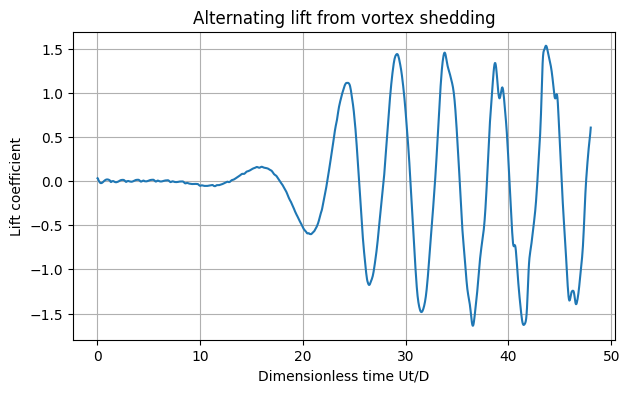

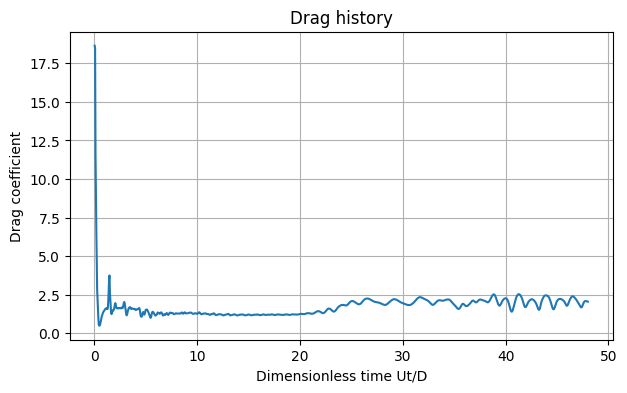

In [5]:
#@title 5. Plot the primary numerical results
history = read_csv(OUT / "cylinder_history.csv")
plt.figure(figsize=(7, 4))
plt.plot(history["dimensionless_time_Ut_over_D"], history["Cl_momentum_exchange"])
plt.xlabel("Dimensionless time Ut/D")
plt.ylabel("Lift coefficient")
plt.title("Alternating lift from vortex shedding")
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history["dimensionless_time_Ut_over_D"], history["Cd_momentum_exchange"])
plt.xlabel("Dimensionless time Ut/D")
plt.ylabel("Drag coefficient")
plt.title("Drag history")
plt.grid(True)
plt.show()

## Inline field visualization

This preview removes the need for ParaView during the basic laboratory workflow. The VTK file is still included in the downloaded results for optional advanced post-processing.

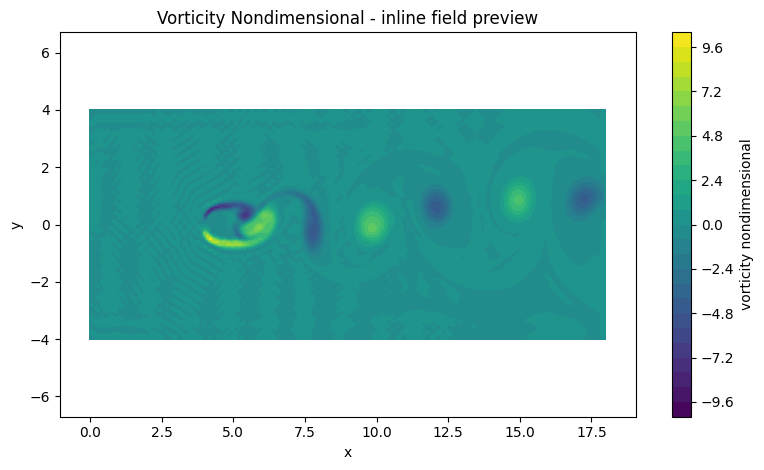

### Generated files
| File | Size |
|---|---:|
| `cylinder_history.csv` | 160.3 KB |
| `cylinder_stream_seeds.vtk` | 1.4 KB |
| `cylinder_summary.txt` | 521 B |
| `cylinder_vortex_000300.vtk` | 2.5 MB |
| `cylinder_vortex_000600.vtk` | 2.5 MB |
| `cylinder_vortex_000900.vtk` | 2.5 MB |
| `cylinder_vortex_001200.vtk` | 2.5 MB |
| `cylinder_vortex_final.vtk` | 2.5 MB |
| `cylinder_wall.vtk` | 15.7 KB |
| `solver_stderr.log` | 0 B |
| `solver_stdout.log` | 1.1 KB |

In [6]:
#@title 6. Display the final field and generated files
plot_vtk_scalar(OUT / 'cylinder_vortex_final.vtk', 'vorticity_nondimensional')
files = list_outputs(OUT)


## Download results

In [7]:
#@title 7. Package and download the results
DOWNLOAD_RESULTS = False #@param {type:"boolean"}
RESULTS_ZIP = make_results_zip(OUT, 4)
if DOWNLOAD_RESULTS:
    if IN_COLAB:
        colab_files.download(str(RESULTS_ZIP))
    else:
        print("Local test mode. Archive retained at:", RESULTS_ZIP)
else:
    print("Set DOWNLOAD_RESULTS to True and run this cell when ready to download.")


Results archive: /content/cfd_lab_exp04/experiment_04_results.zip (3490.0 KB)
Set DOWNLOAD_RESULTS to True and run this cell when ready to download.


## 7. Compulsory assignment

Use the lab preset at $Re=100$. Report the estimated Strouhal number, mean drag, lift amplitude, density deviation, and show a vorticity sequence over one shedding cycle.

## Report checklist

- State the governing equations and boundary conditions.
- Report the complete parameter set and grid.
- Include residual or error history.
- Include the required quantitative comparison.
- Include at least one correctly labelled inline field figure; VTK/ParaView figures are optional unless specifically assigned.
- Distinguish observed numerical behaviour from physical interpretation.
- State the limitations of the supplied teaching model.